In [1]:
# Experiment 02 — Simon's Algorithm

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np

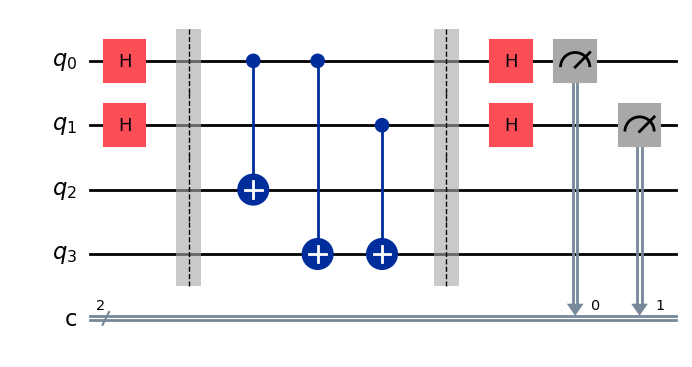

In [3]:
# Define the hidden binary string
secret = "11"
n = len(secret)

# Create two input and two output qubits
qc = QuantumCircuit(2 * n, n)

# Apply Hadamard gates to input qubits
qc.h(range(n))

qc.barrier()

# Create an oracle with hidden string 11
qc.cx(0, 2)
qc.cx(0, 3)
qc.cx(1, 3)

qc.barrier()

# Apply Hadamard gates again
qc.h(range(n))

# Measure the input qubits
qc.measure(range(n), range(n))

# Display the circuit
display(qc.draw("mpl"))

In [4]:
# Run the circuit using AerSimulator
simulator = AerSimulator()

result = simulator.run(
    transpile(qc, simulator),
    shots=1024,
    seed_simulator=42
).result()

counts = result.get_counts()

print("Measurement Counts:", counts)

Measurement Counts: {'10': 278, '01': 272, '11': 231, '00': 243}


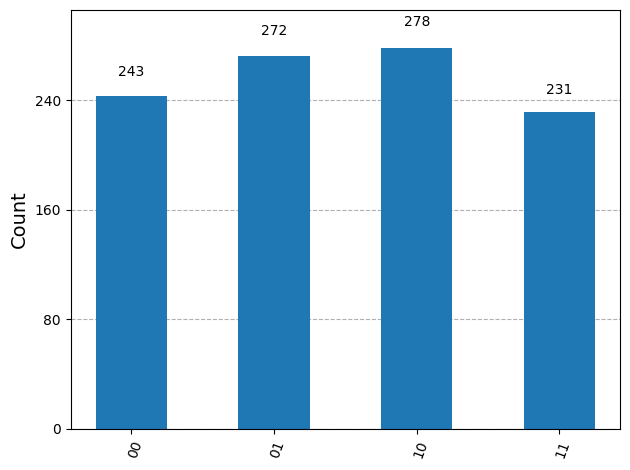

In [5]:
# Display the measurement results
display(plot_histogram(counts))

In [6]:
# Check the condition y . s = 0 (mod 2)
for bits in sorted(counts):
    y = np.array([int(bit) for bit in bits])
    s = np.array([int(bit) for bit in secret])

    dot_product = int(np.dot(y, s) % 2)

    print(f"Measurement: {bits}, Dot Product: {dot_product}")

Measurement: 00, Dot Product: 0
Measurement: 01, Dot Product: 1
Measurement: 10, Dot Product: 1
Measurement: 11, Dot Product: 0


In [7]:
# Find a nonzero measurement result
nonzero_results = [bits for bits in counts if bits != "00"]

if nonzero_results:
    measured = nonzero_results[0]

    # For two bits, find the nonzero string orthogonal to the measurement
    candidates = ["01", "10", "11"]

    recovered = None

    for candidate in candidates:
        dot = sum(
            int(a) * int(b)
            for a, b in zip(measured, candidate)
        ) % 2

        if dot == 0:
            recovered = candidate
            break

    print("Hidden String:", secret)
    print("Recovered String:", recovered)
    print("Result Matches:", recovered == secret)
else:
    print("More measurements are needed.")

Hidden String: 11
Recovered String: 01
Result Matches: False
